# Classificazione di masse mammarie con algoritmi di machine learning
**Angelo Cassella - Matricola 0322600004**

In questo elaborato confronto tre classificatori studiati nel corso e una rete neurale MLP sul dataset Breast Cancer Wisconsin (Diagnostic). L'obiettivo è verificare quanto bene distinguano le masse benigne da quelle maligne, usando lo stesso insieme di test.

Il dataset è adatto a questa esercitazione perché contiene misure numeriche, una classificazione binaria e abbastanza feature da rendere utile l'analisi PCA. Le dimensioni contenute permettono di eseguire l'esperimento anche su un normale computer.

Il percorso segue la traccia: caricamento e preparazione dei dati, PCA (punto 1), tre classificatori (punto 2), metriche e grafici (punti 3-4), rete neurale sugli stessi split (punto 5a). Le implementazioni degli algoritmi sono quelle di scikit-learn: il lavoro consiste nella costruzione e valutazione dell'esperimento, senza riscrivere i solutori da zero.

In [1]:
# Librerie e cartella dove salvare i risultati.
from pathlib import Path
import json, sys, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
 roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from IPython.display import display
OUT=Path('risultati'); OUT.mkdir(exist_ok=True)
SEED=42
print('Python',platform.python_version(),'sklearn',sklearn.__version__)


Python 3.13.18 sklearn 1.6.1


## 1. Caricamento dei dati e preparazione
Le righe sono 569 osservazioni e le colonne sono 30 misure dei nuclei cellulari. Le dieci caratteristiche di base comprendono raggio, area, perimetro, tessitura e regolarità; per ciascuna sono riportati media, errore standard e valori peggiori.

Uso `load_breast_cancer`, che contiene una copia del dataset UCI: il pulsante “Import in Python” del sito propone invece `ucimlrepo`, che recupera i dati via rete. Non occorre usare entrambi. La classe originale 0 (maligno) viene ricodificata come 1: in tutte le metriche, quindi, positivo significa maligno.

Divido i dati in training (60%), validation (20%) e test (20%), mantenendo proporzioni simili delle due classi. Il training serve ad apprendere; la validation a scegliere le impostazioni; il test rimane riservato alla valutazione finale. Il seed 42 rende riproducibile la suddivisione.

Controllo dimensioni, valori mancanti e duplicati. Standardizzo le feature perché hanno scale differenti: media e deviazione standard vengono stimate soltanto sul training. Validation e test vengono trasformati con gli stessi valori, evitando di usare informazioni del test nella preparazione.

In [2]:
# Ricodifica del target e split condivisi da tutti gli algoritmi.
data=load_breast_cancer(as_frame=True)
X=data.data; y=(data.target==0).astype(int)
assert X.shape==(569,30) and not X.isna().any().any()
idx=np.arange(len(X))
tr,te=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)
tr,va=train_test_split(tr,test_size=.25,stratify=y.iloc[tr],random_state=SEED)
assert not(set(tr)&set(va) or set(tr)&set(te) or set(va)&set(te))
np.savez(OUT/'split.npz',train=tr,validation=va,test=te)
X.assign(maligno=y).to_csv(OUT/'dataset.csv',index=False)
display(pd.DataFrame([{'split':k,'n':len(i),'maligni':int(y.iloc[i].sum())} for k,i in [('train',tr),('validation',va),('test',te)]]))
display(X.describe().T)
print('Duplicati feature:',X.duplicated().sum())
scaler=StandardScaler().fit(X.iloc[tr])
A,B,C=[scaler.transform(X.iloc[i]) for i in [tr,va,te]]


,split,n,maligni
0,train,341,127
1,validation,114,43
2,test,114,42


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Duplicati feature: 0


## 2. Analisi delle feature con PCA - punto 1
La PCA combina le feature in nuovi assi che conservano quanta più varianza possibile. Uso i primi due assi per visualizzare i dati e tutte le componenti per calcolare la varianza cumulata. La PCA viene stimata soltanto sul training standardizzato.

La tabella dei coefficienti mostra quali feature contribuiscono maggiormente a PC1. Il segno degli assi può invertirsi senza cambiare il significato della proiezione.

Per la classificazione mantengo le 30 feature originali standardizzate: la PCA qui ha un ruolo esplorativo. Conservare molta varianza non garantisce di conservare tutta l'informazione utile per distinguere le diagnosi.

Varianza prime due: 0.6379951102022516 Componenti al 95%: 10


,PC1,PC2
mean concave points,0.256452,-0.041880
mean concavity,0.254621,0.050110
worst concave points,0.247441,-0.011134
mean compactness,0.238563,0.147247
worst perimeter,0.235696,-0.198755
worst radius,0.226769,-0.220498
mean perimeter,0.226060,-0.216353
worst area,0.223734,-0.221110


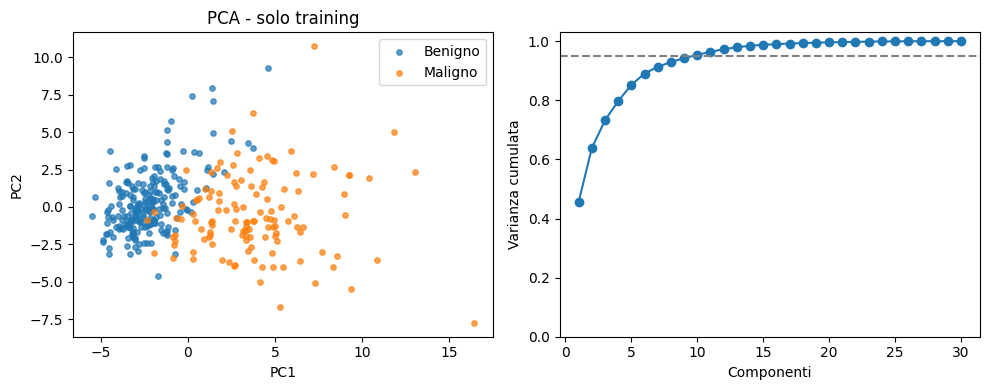

In [3]:
# Stimo la PCA sul training, poi rappresento le prime due componenti.
pca=PCA().fit(A); Z=pca.transform(A)
cum=np.cumsum(pca.explained_variance_ratio_)
print('Varianza prime due:',cum[1], 'Componenti al 95%:',np.searchsorted(cum,.95)+1)
pd.DataFrame({'varianza':pca.explained_variance_ratio_,'cumulata':cum}).to_csv(OUT/'pca.csv',index=False)
loadings=pd.DataFrame(pca.components_[:2].T,index=X.columns,columns=['PC1','PC2'])
loadings.to_csv(OUT/'carichi_pca.csv'); display(loadings.loc[loadings.PC1.abs().nlargest(8).index])
fig,ax=plt.subplots(1,2,figsize=(10,4))
for label,name in [(0,'Benigno'),(1,'Maligno')]:
 mask=y.iloc[tr].to_numpy()==label; ax[0].scatter(Z[mask,0],Z[mask,1],s=15,alpha=.7,label=name)
ax[0].set(xlabel='PC1',ylabel='PC2',title='PCA - solo training'); ax[0].legend()
ax[1].plot(np.arange(1,31),cum,'o-'); ax[1].axhline(.95,color='gray',ls='--'); ax[1].set(xlabel='Componenti',ylabel='Varianza cumulata',ylim=(0,1.03))
fig.tight_layout(); fig.savefig(OUT/'pca.png',dpi=160); plt.show()


## 3. Addestramento e scelta delle impostazioni - punti 2 e 5a
Per il punto 2 confronto tre approcci diversi:
- **Regressione logistica**: un riferimento semplice, con confine lineare e regolarizzazione L2.
- **SVM con kernel RBF**: permette di rappresentare separazioni non lineari.
- **Random Forest**: combina 300 alberi e rappresenta interazioni fra le feature.

Per il punto 5a aggiungo una **MLP con due strati nascosti da 32 e 16 neuroni**, attivazione ReLU e ottimizzatore Adam. L'uscita fornisce il punteggio della classe maligna. La rete usa esattamente gli stessi split degli altri algoritmi; non viene creato un ulteriore insieme interno per early stopping.

Provo un numero limitato di impostazioni: C per logistica, C e gamma per SVM, profondità e dimensione minima delle foglie per Random Forest, alpha per MLP. Scelgo la configurazione con AUC maggiore sulla validation; in caso di parità resta la prima incontrata. Il confronto è esplorativo, non una ricerca esaustiva. Il ciclo permette di applicare lo stesso criterio a tutti i modelli.

La soglia di classificazione resta 0.5. I modelli selezionati non vengono riaddestrati sulla validation.

In [4]:
# Ogni candidato apprende dal training; la validation decide quale mantenere.
specs={
'Logistica':(LogisticRegression,{'C':[.1,1,10]},dict(max_iter=2000,random_state=SEED)),
'SVM':(SVC,{'C':[.1,1,10],'gamma':['scale',.01]},dict(probability=True,random_state=SEED)),
'Random Forest':(RandomForestClassifier,{'max_depth':[3,None],'min_samples_leaf':[1,3]},dict(n_estimators=300,random_state=SEED,n_jobs=1)),
'MLP':(MLPClassifier,{'alpha':[.0001,.01]},dict(hidden_layer_sizes=(32,16),activation='relu',solver='adam',max_iter=2000,random_state=SEED,early_stopping=False))}
models={}; search=[]
for name,(cls,grid,fixed) in specs.items():
 best=-np.inf
 for params in ParameterGrid(grid):
  model=cls(**fixed,**params).fit(A,y.iloc[tr])
  auc=roc_auc_score(y.iloc[va],model.predict_proba(B)[:,1])
  search.append({'modello':name,'parametri':str(params),'AUC_validation':auc})
  if auc>best: best=auc; models[name]=model
search=pd.DataFrame(search); search.to_csv(OUT/'ricerca.csv',index=False); display(search)
print('Modello scelto prima del test:',max(models,key=lambda k:roc_auc_score(y.iloc[va],models[k].predict_proba(B)[:,1])))


,modello,parametri,AUC_validation
0,Logistica,{'C': 0.1},0.995087
1,Logistica,{'C': 1},0.995742
2,Logistica,{'C': 10},0.995742
3,SVM,"{'C': 0.1, 'gamma': 'scale'}",0.992139
4,SVM,"{'C': 0.1, 'gamma': 0.01}",0.990501
5,SVM,"{'C': 1, 'gamma': 'scale'}",0.996069
6,SVM,"{'C': 1, 'gamma': 0.01}",0.995414
7,SVM,"{'C': 10, 'gamma': 'scale'}",0.996069
8,SVM,"{'C': 10, 'gamma': 0.01}",0.995742
9,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 1}",0.989191


Modello scelto prima del test: MLP


## 4. Valutazione sul test - punti 3 e 4
Ora utilizzo il test, dopo avere scelto le impostazioni. Calcolo accuracy, precision, recall, F1 e ROC AUC per ciascun modello.

Con maligno=1, TP indica un maligno riconosciuto, FN un maligno classificato come benigno, FP un benigno classificato come maligno e TN un benigno riconosciuto.

Verifico anche le formule di accuracy, precision, recall e F1 a partire dai conteggi della matrice di confusione. La ROC AUC è calcolata sui punteggi continui, mentre le altre metriche usano la soglia 0.5. Questo spiega perché il modello con AUC più alta può non avere la migliore accuracy.

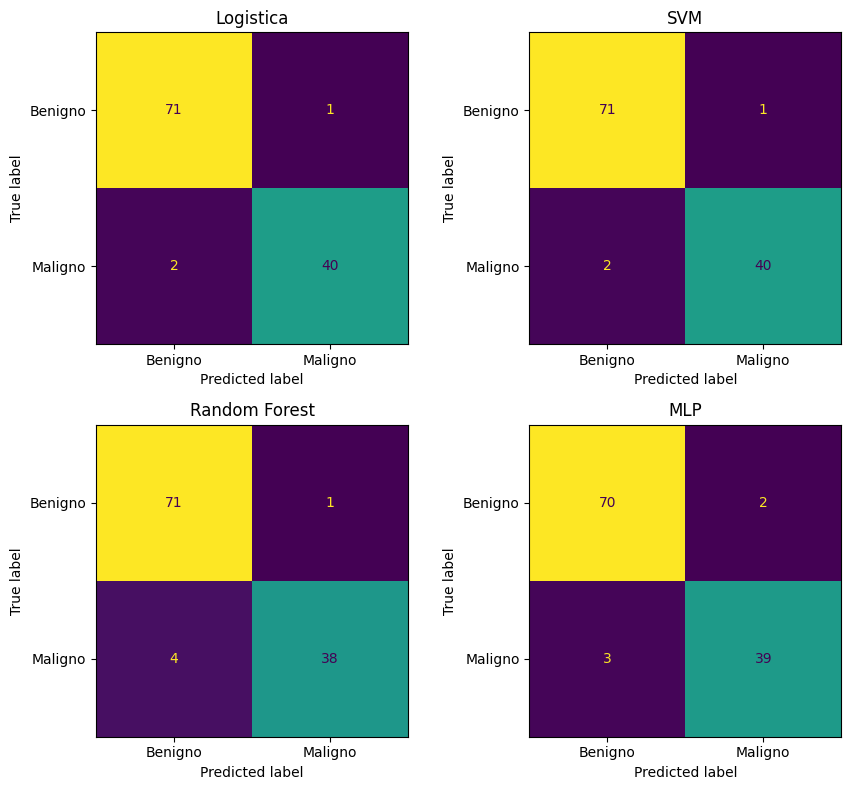

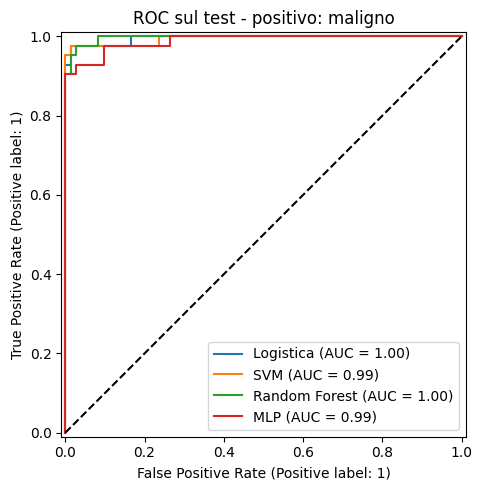

,modello,accuracy,precision,recall,F1,AUC,TN,FP,FN,TP
0,Logistica,0.973684,0.975610,0.952381,0.963855,0.995370,71,1,2,40
1,SVM,0.973684,0.975610,0.952381,0.963855,0.994048,71,1,2,40
2,Random Forest,0.956140,0.974359,0.904762,0.938272,0.996693,71,1,4,38
3,MLP,0.956140,0.951220,0.928571,0.939759,0.988426,70,2,3,39


MLP iterazioni: 305


In [5]:
# Il test viene usato dopo la selezione. Salvo anche le singole predizioni.
rows=[]; fig,axes=plt.subplots(2,2,figsize=(9,8)); rocfig,rocax=plt.subplots(figsize=(7,5))
for ax,(name,model) in zip(axes.flat,models.items()):
 score=model.predict_proba(C)[:,1]; pred=(score>=.5).astype(int)
 tn,fp,fn,tp=confusion_matrix(y.iloc[te],pred).ravel()
 manual=[(tp+tn)/len(te),tp/(tp+fp) if tp+fp else 0,tp/(tp+fn),2*tp/(2*tp+fp+fn)]
 vals=[accuracy_score(y.iloc[te],pred),precision_score(y.iloc[te],pred,zero_division=0),recall_score(y.iloc[te],pred),f1_score(y.iloc[te],pred)]
 assert np.allclose(manual,vals)
 rows.append(dict(modello=name,accuracy=vals[0],precision=vals[1],recall=vals[2],F1=vals[3],AUC=roc_auc_score(y.iloc[te],score),TN=tn,FP=fp,FN=fn,TP=tp))
 ConfusionMatrixDisplay.from_predictions(y.iloc[te],pred,display_labels=['Benigno','Maligno'],ax=ax,colorbar=False); ax.set_title(name)
 RocCurveDisplay.from_predictions(y.iloc[te],score,name=name,ax=rocax)
 pd.DataFrame({'indice':te,'vero':y.iloc[te].values,'score':score,'predetto':pred}).to_csv(OUT/(name.replace(' ','_')+'_predizioni.csv'),index=False)
fig.tight_layout(); fig.savefig(OUT/'confusione.png',dpi=160)
rocax.plot([0,1],[0,1],'k--'); rocax.set_title('ROC sul test - positivo: maligno'); rocfig.tight_layout(); rocfig.savefig(OUT/'roc.png',dpi=160)
plt.show()
results=pd.DataFrame(rows); results.to_csv(OUT/'metriche.csv',index=False); display(results)
print('MLP iterazioni:',models['MLP'].n_iter_)


## 5. Lettura dei risultati
Le prime due componenti della PCA spiegano circa il 63,8% della varianza; per superare il 95% ne servono 10. Nel piano si osservano gruppi parzialmente distinti, ma anche sovrapposizioni: il grafico non dimostra una separazione perfetta nelle 30 dimensioni.

La MLP è il modello scelto sulla validation (AUC circa 0,9967). Sul test, però, logistica e SVM ottengono 111 classificazioni corrette su 114 (97,37%), mentre Random Forest e MLP ne ottengono 109 (95,61%). Questa differenza non autorizza a cambiare retroattivamente il criterio di selezione.

Per la logistica, i 42 maligni del test sono suddivisi in 40 veri positivi e 2 falsi negativi. Dei 72 benigni, 71 sono corretti e uno è un falso positivo. Quindi precision=40/41, recall=40/42 e accuracy=111/114. La MLP presenta invece 3 falsi negativi e 2 falsi positivi.

Random Forest ha la migliore AUC di test (0,9967), ma commette 4 falsi negativi alla soglia 0,5. AUC e recall non sono intercambiabili: la prima valuta l'ordinamento dei punteggi, la seconda il risultato della decisione a una soglia precisa.

Il risultato più utile del confronto è che la maggiore complessità della rete non porta automaticamente a una migliore classificazione su questo split. Una differenza di due casi è piccola e richiede prudenza nell'interpretazione.


## Limiti e riferimenti
Un singolo split non quantifica la variabilità. Servirebbero cross-validation ripetuta, intervalli di confidenza e una coorte esterna. I falsi negativi sono particolarmente rilevanti nel contesto diagnostico; la soglia andrebbe scelta su validation secondo costi espliciti. La PCA è descrittiva e non dimostra causalità. Dataset storico e selezionato: nessuna conclusione sull’impiego clinico.

UCI: https://doi.org/10.24432/C5DW2B (Wolberg et al., 1993), licenza CC BY 4.0. Copia dati: sklearn.datasets.load_breast_cancer. Riferimenti didattici: slide 5 (metriche), 14 (SVM), 16 (Random Forest), 19 (regressione logistica), 24 (PCA), 28 (MLP). Documentazione: https://scikit-learn.org/stable/ .